# GE5219 full workflow: raw inputs to explainable recommendations
Default **Run All needs neither network nor a token**: read actual raw files; use existing real routes to rebuild the matrix, refit A-only P5/P95 and recompute recommendations; reanalyse completed 1,000 Monte Carlo draws and 84 OAT settings. Default execution does not rescore 1,000 draws.

Install Python 3.11+ and Jupyter following the code structure guide and select that environment as the kernel. Start from the package root or notebooks/. Keep raw_data/, src/, config/ and outputs/ together. Place names and indicator identifiers match the CSVs.

## 1. Environment and switches
All optional switches default to False. Reruns write only under outputs/notebook_recomputed/. The API branch requests at most **one unique origin**, with up to three HTTP attempts per client call, never 2,196 origins automatically. Only the client reads ONEMAP_TOKEN; the notebook does not read or print it.

In [1]:
from pathlib import Path
from dataclasses import asdict
from datetime import datetime
import hashlib
import json
import sys
import time
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from IPython.display import JSON, display
from pandas.testing import assert_frame_equal

RUN_PREPARE = False
RUN_API = False
RUN_FULL_EXPERIMENTS = False

assert sys.version_info >= (3, 11)
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file() and (p / "src" / "ge5219").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start from the package root or notebooks/.")
sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "raw_data"
PREPARED = ROOT / "outputs" / "prepared"
EXPERIMENTS = ROOT / "outputs" / "experiments"
RECOMPUTED = ROOT / "outputs" / "notebook_recomputed"

from ge5219.artifacts import read_locations
from ge5219.experiments import compare_rankings, compare_spatial_selections
from ge5219.mcda import fit_normalization, normalize_indicators, recommend
from ge5219.pipeline import assemble_matrix
from ge5219.routing import (
    OneMapClient, SQLiteRouteCache, load_destination, route_locations, route_request,
)
from ge5219.settings import ANALYSIS_VERSION, DEPARTURE, FEATURES, SCENARIOS

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

frozen_paths = [
    *sorted(PREPARED.rglob("*")), *sorted((ROOT / "outputs" / "score").glob("*")),
    *sorted(EXPERIMENTS.rglob("*")), ROOT / "outputs" / "routes.csv",
    ROOT / "outputs" / "normalization-v1.json", *sorted((ROOT / "config").glob("*.json")),
]
frozen_hashes = {p: sha256(p) for p in frozen_paths if p.is_file()}
started = time.perf_counter()
pd.set_option("display.max_columns", 16)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
display(pd.DataFrame({
    "switch": ["RUN_PREPARE", "RUN_API", "RUN_FULL_EXPERIMENTS"],
    "enabled": [RUN_PREPARE, RUN_API, RUN_FULL_EXPERIMENTS],
}))

,switch,enabled
0,RUN_PREPARE,False
1,RUN_API,False
2,RUN_FULL_EXPERIMENTS,False


## 2. Actual raw inventory and source binding
Walk raw_data/, query GDB/GPKG layers, feature counts, geometry types and CRS directly; read the entire raw residential CSV and five residential GDB geometries. Prepared caches are not presented as raw reads. Z/M warnings describe driver handling of geometry dimensions; computation uses two-dimensional metres in EPSG:3414.

Earlier routes, ZIPs, density rasters and the source notebook are preserved for traceability without becoming current commute measurements. Recalculate every source_manifest SHA256 from actual raw files.

In [2]:
if not (RAW / "GE5219_Indicators.gdb").is_dir():
    raise FileNotFoundError("Complete package requires raw_data/GE5219_Indicators.gdb/.")
raw_files = pd.DataFrame([
    {"path": p.relative_to(RAW).as_posix(), "bytes": p.stat().st_size}
    for p in sorted(RAW.rglob("*")) if p.is_file()
])
display(raw_files)
layer_rows = []
with warnings.catch_warnings(record=True) as geometry_warnings:
    warnings.simplefilter("always")
    for source in [RAW / "GE5219_Indicators.gdb", *sorted(RAW.rglob("*.gpkg"))]:
        for layer_name, geometry_type in pyogrio.list_layers(source):
            info = pyogrio.read_info(source, layer=layer_name, force_feature_count=True)
            layer_rows.append({
                "source": source.relative_to(RAW).as_posix(), "layer": layer_name,
                "features": int(info["features"]), "geometry_type": geometry_type,
                "crs": str(info["crs"]),
            })
    source_geometry_sample = gpd.read_file(
        RAW / "GE5219_Indicators.gdb", layer="HDB_Point", rows=5,
    )
layer_inventory = pd.DataFrame(layer_rows)
display(layer_inventory)
display(source_geometry_sample.head())
display(pd.DataFrame({"driver_warning": sorted({str(w.message) for w in geometry_warnings})}))
source_csv = RAW / "GE5219_B_Handover" / "01_Data" / "Residential_Accessibility_API.csv"
raw_residences = pd.read_csv(source_csv, dtype="string")
display(raw_residences.head())
display(raw_residences["Residential_Type"].value_counts().rename("source_records").to_frame())
source_manifest = read_json(PREPARED / "source_manifest.json")
source_hash_matches = {
    relative: sha256(PREPARED / Path(relative).name
                     if relative.startswith("analysis_config/") else RAW / relative) == expected
    for relative, expected in source_manifest.items()
}
assert all(source_hash_matches.values()), "Raw sources differ from frozen preparation."
for relative in source_manifest:
    if relative.startswith("analysis_config/"):
        assert read_json(ROOT / "config" / Path(relative).name) == read_json(PREPARED / Path(relative).name)
quality = read_json(PREPARED / "data_quality.json")
assert len(raw_residences) == quality["source_records"]
assert sha256(source_csv) == quality["source_csv_sha256"]
gdb_housing = layer_inventory[layer_inventory.source.eq("GE5219_Indicators.gdb")
                              & layer_inventory.layer.isin(["HDB_Point", "Dwelling"])]
assert gdb_housing.features.sum() == len(raw_residences)
display(JSON({
    "raw_file_count": len(raw_files), "raw_bytes": int(raw_files.bytes.sum()),
    "source_manifest_files_verified": len(source_hash_matches),
    "source_csv_records_read": len(raw_residences), "raw_layers_inspected": len(layer_inventory),
}))

,path,bytes
0,GE5219 B Handover Oct15_15.zip,42631055
1,GE5219_B_Handover/01_Data/Residential_Accessib...,40583186
2,GE5219_B_Handover/01_Data/Transit_Travel_Time_...,682
3,GE5219_B_Handover/01_Data/Transit_Travel_Time_...,830
4,GE5219_B_Handover/01_Data/Transit_Travel_Time_...,830
...,...,...
171,GE5219_Indicators.gdb/a00000016.horizon,32
172,GE5219_Indicators.gdb/a00000016.spx,4118
173,GE5219_Indicators.gdb/gdb,4
174,GE5219_Indicators.gdb/timestamps,400


,source,layer,features,geometry_type,crs
0,GE5219_Indicators.gdb,Dwelling,83541,Point Z,EPSG:4326
1,GE5219_Indicators.gdb,Gym,159,Point Z,EPSG:4326
2,GE5219_Indicators.gdb,Hawker_Centre,129,Point Z,EPSG:4326
3,GE5219_Indicators.gdb,HDB_Point,13436,Point Z,EPSG:4326
4,GE5219_Indicators.gdb,HDB_Polygon,13436,MultiPolygon Z,EPSG:4326
5,GE5219_Indicators.gdb,Healthcare,1192,Point Z,EPSG:4326
6,GE5219_Indicators.gdb,Library,26,Point Z,EPSG:4326
7,GE5219_Indicators.gdb,Park_Point,462,Point Z,EPSG:4326
8,GE5219_Indicators.gdb,Parks_and_Nature,462,MultiPolygon Z,EPSG:4326
9,GE5219_Indicators.gdb,Subzone,332,MultiPolygon Z,EPSG:4326


,OBJECTID_1,BLK_NO,ST_COD,ENTITYID,POSTAL_COD,INC_CRC,FMEL_UPD_D,ORIG_FID,geometry
0,948044.0,277,TOG02Q,8003.0,600277,F1B655758EC024BF,20130426120325,0,POINT Z (103.74684 1.34132 0)
1,948045.0,625,SEN12T,4014.0,670625,CBB1D553BADFE5A0,20130426120322,1,POINT Z (103.76036 1.38563 0)
2,948046.0,296,COC08K,4089.0,540296,1718DE0265076129,20130426120238,2,POINT Z (103.89907 1.39712 0)
3,948047.0,232,SUL11B,11051440.0,820232,A39A45CAEAF78B83,20210105152826,3,POINT Z (103.89007 1.40178 0)
4,948048.0,41,HOD00F,6521.0,270041,BA6DBA24022D6C44,20130426120311,4,POINT Z (103.79346 1.30762 0)


,driver_warning
0,Measured (M) geometry types are not supported....
1,Measured (M) geometry types are not supported....


,BusStop_Count_800,TARGET_FID,OBJECTID_1,BLK_NO,ST_COD,ENTITYID,POSTAL_COD,INC_CRC,...,OBJECTID_12_13,BUS_STOP_NUM_1,BUS_ROOF_NUM_1,UNIQUE_ID_1,INC_CRC_12,FMEL_UPD_D_12,Latitude,Longitude
0,30,1,948044.000000000000000,277,TOG02Q,8003.000000000000000,600277,F1B655758EC024BF,...,165996.000000000000000,43591,B05,19990.000000000000000,9FA8951342CFF698,20260826143539,1.341318922926329,103.746725723650798
1,39,2,948045.000000000000000,625,SEN12T,4014.000000000000000,670625,CBB1D553BADFE5A0,...,164377.000000000000000,44631,B01,20157.000000000000000,7CC36F9C3C625F6A,20260826143538,1.385634061070126,103.760361050565265
2,42,3,948046.000000000000000,296,COC08K,4089.000000000000000,540296,1718DE0265076129,...,164697.000000000000000,67759,UNK,22023.000000000000000,1A7EBD07B293DC88,20260826143542,1.397119249595882,103.899072077690363
3,24,4,948047.000000000000000,232,SUL11B,11051440.000000000000000,820232,A39A45CAEAF78B83,...,164698.000000000000000,67761,B02A,22024.000000000000000,4532D8C346C8F70D,20260826143542,1.401779380114772,103.890073295343200
4,25,5,948048.000000000000000,41,HOD00F,6521.000000000000000,270041,BA6DBA24022D6C44,...,168253.000000000000000,11351,B01,18397.000000000000000,B1F4921E00CD874A,20260826143540,1.307620048684320,103.793463529957208


,source_records
Residential_Type,
Condo,83541
HDB,13436


<IPython.core.display.JSON object>

## 3. Spatial preparation, QC and frozen A/B
Housing → source mapping/postal conflict holdout → Subzones → 400m grid sample A → supplements for uncovered 150m connected clusters, forming B → six static indicators. A=2,176 and B=2,196. B is the full planned origin table. A 150m chain can span kilometres; clusters are not verified estates.

Default execution reads completed preparation QC, raw static measurements and memberships. RUN_PREPARE=True reruns preparation from raw sources into a new directory without replacing the frozen baseline below. This can take minutes without continuous output.

In [3]:
if RUN_PREPARE:
    from ge5219.spatial import prepare_data
    display(JSON(prepare_data(RAW, RECOMPUTED / "prepared")))
locations = read_locations(PREPARED / "analysis_locations.csv")
static = read_locations(PREPARED / "static_indicators.csv")
members = read_locations(PREPARED / "cluster_membership.csv")
assert len(locations) == quality["sample_B_count"] == 2196
assert int(locations.sample_A.sum()) == quality["sample_A_count"] == 2176
assert len(locations) - int(locations.sample_A.sum()) == quality["supplement_count"] == 20
assert members.building_id.nunique() == quality["candidate_records"] == 96763
assert locations.area_id.nunique() == quality["area_count"] == 241
assert members.cluster_id.nunique() == quality["cluster_count"] == 384
qc_keys = ["source_records", "candidate_records", "held_out_records", "conflict_postal_codes",
           "sample_A_count", "sample_B_count", "supplement_count", "area_count", "cluster_count"]
display(pd.DataFrame({"measure": qc_keys, "observed": [quality[k] for k in qc_keys]}))
display(pd.DataFrame({"readiness_blocker": quality["readiness_blockers"]}))
display(static[["location_id", "area_name", "cluster_id", "sample_A", *FEATURES[1:]]].head(10))
display(static[list(FEATURES[1:])].describe().T)
display(locations.groupby("area_name").agg(
    n_B=("location_id", "size"), n_A=("sample_A", "sum"),
).sort_values("n_B", ascending=False).head(12))

,measure,observed
0,source_records,96977
1,candidate_records,96763
2,held_out_records,214
3,conflict_postal_codes,107
4,sample_A_count,2176
5,sample_B_count,2196
6,supplement_count,20
7,area_count,241
8,cluster_count,384


,readiness_blocker
0,107 postal conflicts require adjudication; hel...
1,Residential use is source-classification evide...
2,Identified unopened station excluded; remainin...
3,Non-reserve park/corridor categories and publi...
4,"Facility address precision, licence grouping a..."
5,"Destination review, public-transit coverage an..."


,location_id,area_name,cluster_id,sample_A,rail_exit_euclid_m,bus_stops_800m,supermarket_sites_800m,library_euclid_m,clinic_sites_1000m,park_proximity_euclid_m
0,LOC_BLD_000d4f886a7311338eff,WOODLANDS SOUTH,WDSZ04_C_72f0c04846a6,True,308.201051,57,4,545.438591,18,901.974842
1,LOC_BLD_0011ce850ebdfe00624e,YUNNAN,JWSZ08_C_ca87ed04d523,True,1143.528290,30,1,1785.555483,10,772.035524
2,LOC_BLD_001aec0fd2dded056c26,BIDADARI,TPSZ10_C_17cc7895ad26,True,446.294233,39,0,892.654390,5,164.930730
3,LOC_BLD_001d63fa94fe1c577bc8,TIONG BAHRU,BMSZ10_C_d3de8facfbb7,True,521.571776,24,5,1815.852638,24,199.174292
4,LOC_BLD_0058187dc2c0a4587091,WOODLANDS EAST,WDSZ03_C_5cbce1649948,True,331.182595,39,3,1772.377986,17,1705.224161
5,LOC_BLD_006184e9dc2488685b56,KAMPONG BUGIS,KLSZ04_C_7feb03dcd605,True,352.962305,24,3,2044.052141,9,27.173725
6,LOC_BLD_0079d5f15eef78351d65,LORONG AH SOO,HGSZ07_C_35d68fa5c113,True,218.149878,29,3,1464.821490,14,514.836953
7,LOC_BLD_00849be18def8753be9f,MARYMOUNT,BSSZ02_C_b8ecdb79c2f8,True,752.593466,28,2,883.622881,16,7.794179
8,LOC_BLD_009c740cc9351baf2936,YUHUA WEST,JESZ01_C_f6eb06b39e6a,True,983.403203,25,2,2048.330161,14,734.526489
9,LOC_BLD_00cf59ee76df1ef7ef89,CLEMENTI WOODS,CLSZ07_C_edf504c93dcc,True,1718.026245,39,1,2214.237246,2,181.825960


,count,mean,std,min,25%,50%,75%,max
rail_exit_euclid_m,2196.0,632.284102,467.253817,15.325058,307.409448,533.452334,813.262582,3619.763125
bus_stops_800m,2196.0,29.668944,11.173152,0.000000,23.000000,30.000000,37.000000,60.000000
supermarket_sites_800m,2196.0,2.937614,2.178634,0.000000,1.000000,3.000000,4.000000,12.000000
library_euclid_m,2196.0,1474.465563,804.126693,0.422530,874.243275,1363.281194,1919.733608,4782.148656
clinic_sites_1000m,2196.0,13.433515,8.819044,0.000000,7.000000,12.000000,19.000000,48.000000
park_proximity_euclid_m,2196.0,378.925547,317.781831,4.979410,144.716242,296.401781,539.450639,2318.874843


,n_B,n_A
area_name,,
TAMPINES EAST,37,36
FRANKEL,34,34
BEDOK SOUTH,29,29
BEDOK NORTH,28,28
TAMPINES WEST,27,27
ALJUNIED,26,26
SERANGOON GARDEN,25,25
LEEDON PARK,24,23
HOLLAND ROAD,24,24


## 4. Routing semantics and a safe one-origin example
Frozen scene: public transport to NUS AS8 at 2026-10-19 08:00 Asia/Singapore. The endpoint is a **building ground-arrival proxy**, supported by official address and route desktop review, not a surveyed entrance. Final network geometry ends about 12.44m from the geocode. Indoor walking, lift access and the exact door remain unverified.

The indicator is **plan.itineraries[0].duration / 60**, the first itinerary's reported seconds converted to minutes. Initial scheduling time between requested departure and actual itinerary start is **not automatically added**. Missing components stay unknown; other itineraries and straight-line estimates never replace duration. Construct non-secret parameters without a client or network call. RUN_API tries one origin in an isolated cache without replacing full routes.csv. Version time, destination or itinerary changes explicitly.

In [4]:
destination = load_destination(ROOT / "config" / "destination.json")
first_origin = locations.iloc[0]
safe_request = route_request(
    (first_origin.latitude, first_origin.longitude), destination, DEPARTURE,
)
departure_time = datetime.fromisoformat(safe_request["departure"])
request_parameters = {
    "start": f"{safe_request['origin_lat']!r},{safe_request['origin_lon']!r}",
    "end": f"{safe_request['destination_lat']!r},{safe_request['destination_lon']!r}",
    "routeType": "pt", "date": departure_time.strftime("%m-%d-%Y"),
    "time": departure_time.strftime("%H:%M:%S"), "mode": "TRANSIT",
    "maxWalkDistance": 1000, "numItineraries": 1,
}
display(JSON({"endpoint": "https://www.onemap.gov.sg/api/public/routingsvc/route",
              "parameters_without_credentials": request_parameters,
              "destination": asdict(destination)}))
if RUN_API:
    client = OneMapClient()
    RECOMPUTED.mkdir(parents=True, exist_ok=True)
    with SQLiteRouteCache(RECOMPUTED / "pilot_routes.sqlite") as cache:
        pilot_routes = route_locations(
            locations.head(1), destination, cache, client, departure=DEPARTURE,
            mode="TRANSIT", max_requests=1, min_interval_seconds=1.0, retry_no_route=False,
        )
    pilot_routes.to_csv(RECOMPUTED / "pilot_routes.csv", index=False)
    display(pilot_routes[["location_id", "route_status", "campus_transit_min"]])

<IPython.core.display.JSON object>

## 5. Reassemble seven indicators from real routes.csv
assemble_matrix left-joins all planned origins and validates origin, destination, departure and mode. Failed rows stay in denominators with NaN minutes. Actually rebuild and compare with frozen indicator_matrix.csv. The snapshot has 2,190 successful first itineraries and six explicit NoRoute responses. Metadata matches the main CLI's hashes and scene for exact result_id reproduction.

In [5]:
routes_path = ROOT / "outputs" / "routes.csv"
routes = read_locations(routes_path)
matrix = assemble_matrix(static, routes, asdict(destination))
frozen_matrix = read_locations(ROOT / "outputs" / "score" / "indicator_matrix.csv")

def assert_same_table(actual, expected, keys):
    assert set(actual.columns) == set(expected.columns)
    left = actual.sort_values(keys).reset_index(drop=True)[sorted(actual.columns)]
    right = expected.sort_values(keys).reset_index(drop=True)[sorted(expected.columns)]
    for column in left.columns:
        if pd.api.types.is_numeric_dtype(left[column]) and pd.api.types.is_numeric_dtype(right[column]):
            left[column] = left[column].astype("float64")
            right[column] = right[column].astype("float64")
        else:
            left[column] = left[column].astype(object).where(left[column].notna(), None)
            right[column] = right[column].astype(object).where(right[column].notna(), None)
    assert_frame_equal(left, right, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)

assert_same_table(matrix, frozen_matrix, ["location_id"])
assert matrix.route_status.value_counts().to_dict() == {"Success": 2190, "NoRoute": 6}
assert matrix.loc[~matrix.route_status.eq("Success"), FEATURES[0]].isna().all()
baseline = matrix.loc[matrix.sample_A].copy()
context = {
    "dataset_version": quality["dataset_version"],
    "static_measurements_sha256": sha256(PREPARED / "static_indicators.csv"),
    "analysis_version": ANALYSIS_VERSION, "destination_id": destination.destination_id,
    "departure": DEPARTURE, "destination": asdict(destination), "data_quality": quality,
    "sampling_limit": "Real sampled positions, not measurements at every building",
    "source_routes_sha256": sha256(routes_path),
}
context_A = {**context, "sample_set": "A"}
display(matrix.route_status.value_counts().rename("n").to_frame())
display(matrix[["location_id", "sample_A", "route_status", *FEATURES]].head(10))
display(matrix[list(FEATURES)].describe().T)

,n
route_status,
Success,2190
NoRoute,6


,location_id,sample_A,route_status,campus_transit_min,rail_exit_euclid_m,bus_stops_800m,supermarket_sites_800m,library_euclid_m,clinic_sites_1000m,park_proximity_euclid_m
0,LOC_BLD_000d4f886a7311338eff,True,Success,65.950000,308.201051,57,4,545.438591,18,901.974842
1,LOC_BLD_0011ce850ebdfe00624e,True,Success,50.533333,1143.528290,30,1,1785.555483,10,772.035524
2,LOC_BLD_001aec0fd2dded056c26,True,Success,50.616667,446.294233,39,0,892.654390,5,164.930730
3,LOC_BLD_001d63fa94fe1c577bc8,True,Success,47.900000,521.571776,24,5,1815.852638,24,199.174292
4,LOC_BLD_0058187dc2c0a4587091,True,Success,62.850000,331.182595,39,3,1772.377986,17,1705.224161
5,LOC_BLD_006184e9dc2488685b56,True,Success,56.716667,352.962305,24,3,2044.052141,9,27.173725
6,LOC_BLD_0079d5f15eef78351d65,True,Success,51.933333,218.149878,29,3,1464.821490,14,514.836953
7,LOC_BLD_00849be18def8753be9f,True,Success,51.100000,752.593466,28,2,883.622881,16,7.794179
8,LOC_BLD_009c740cc9351baf2936,True,Success,41.616667,983.403203,25,2,2048.330161,14,734.526489
9,LOC_BLD_00cf59ee76df1ef7ef89,True,Success,4.850000,1718.026245,39,1,2214.237246,2,181.825960


,count,mean,std,min,25%,50%,75%,max
campus_transit_min,2190.0,56.606499,18.194587,4.850000,44.787500,55.375000,69.237500,116.900000
rail_exit_euclid_m,2196.0,632.284102,467.253817,15.325058,307.409448,533.452334,813.262582,3619.763125
bus_stops_800m,2196.0,29.668944,11.173152,0.000000,23.000000,30.000000,37.000000,60.000000
supermarket_sites_800m,2196.0,2.937614,2.178634,0.000000,1.000000,3.000000,4.000000,12.000000
library_euclid_m,2196.0,1474.465563,804.126693,0.422530,874.243275,1363.281194,1919.733608,4782.148656
clinic_sites_1000m,2196.0,13.433515,8.819044,0.000000,7.000000,12.000000,19.000000,48.000000
park_proximity_euclid_m,2196.0,378.925547,317.781831,4.979410,144.716242,296.401781,539.450639,2318.874843


## 6. Fit P5/P95 only on A and hold them fixed
Use observed nonnegative measurements; commute also requires Success. Benefit normalization is clip((x−P5)/(P95−P5),0,1), and cost normalization is one minus that value. Clipping never imputes missing data. Constant or undefined bounds raise errors. Refit all seven bounds and check the A-measurement fingerprint. Weights, caps, A/B and grouping never refit bounds below.

In [6]:
params = fit_normalization(baseline)
frozen_normalization = read_json(ROOT / "outputs" / "normalization-v1.json")
for feature in FEATURES:
    assert params[feature]["direction"] == frozen_normalization["parameters"][feature]["direction"]
    np.testing.assert_allclose(
        [params[feature]["p05"], params[feature]["p95"]],
        [frozen_normalization["parameters"][feature]["p05"],
         frozen_normalization["parameters"][feature]["p95"]], rtol=1e-14, atol=1e-14,
    )
baseline_fingerprint = hashlib.sha256(pd.util.hash_pandas_object(
    baseline.sort_values("location_id")[["location_id", *FEATURES, "route_status"]], index=False,
).to_numpy().tobytes()).hexdigest()
assert baseline_fingerprint == frozen_normalization["baseline_measurements_sha256"]
assert quality["dataset_version"] == frozen_normalization["dataset_version"]
normalized = normalize_indicators(matrix, params)
display(pd.DataFrame(params).T)
display(normalized[["location_id", FEATURES[0], "z_" + FEATURES[0]]].head(10))

,p05,p95,direction
campus_transit_min,28.125833,87.501667,cost
rail_exit_euclid_m,117.219198,1552.803871,cost
bus_stops_800m,11.0,48.0,benefit
supermarket_sites_800m,0.0,7.0,benefit
library_euclid_m,385.542751,3036.189039,cost
clinic_sites_1000m,1.0,30.0,benefit
park_proximity_euclid_m,32.246482,965.581336,cost


,location_id,campus_transit_min,z_campus_transit_min
0,LOC_BLD_000d4f886a7311338eff,65.950000,0.362970
1,LOC_BLD_0011ce850ebdfe00624e,50.533333,0.622616
2,LOC_BLD_001aec0fd2dded056c26,50.616667,0.621212
3,LOC_BLD_001d63fa94fe1c577bc8,47.900000,0.666966
4,LOC_BLD_0058187dc2c0a4587091,62.850000,0.415180
5,LOC_BLD_006184e9dc2488685b56,56.716667,0.518477
6,LOC_BLD_0079d5f15eef78351d65,51.933333,0.599037
7,LOC_BLD_00849be18def8753be9f,51.100000,0.613072
8,LOC_BLD_009c740cc9351baf2936,41.616667,0.772789
9,LOC_BLD_00cf59ee76df1ef7ef89,4.850000,1.000000


## 7. Recompute the baseline and verify the whole bundle
Only complete seven-dimensional points meeting any raw-minute cap contribute. Areas require valid_share=n_valid/n_planned ≥90% and verified_feasible_share=n_feasible/n_planned ≥50%; failures stay in denominators. Scores and contributions average the same feasible points. The uncapped baseline does not mean “within 60 minutes.”

Rank by unrounded score, then raw mean commute, rail distance and unit_id. n_valid<3 retains limited_support; high rank does not remove sparse support. Verify all point_scores, area_scores, top5 and result_id against the saved bundle, with 1e−12 floating tolerance.

In [7]:
verified_bundles = []

def verify_bundle(result, folder):
    stored_metadata = read_json(folder / "result_metadata.json")
    assert result["metadata"]["result_id"] == stored_metadata["result_id"], folder.name
    for table, keys in [
        ("point_scores", ["location_id"]), ("area_scores", ["unit_id"]), ("top5", ["unit_id"]),
    ]:
        stored = read_locations(folder / f"{table}.csv")
        assert_same_table(result[table], stored, keys)
        assert result[table].result_id.eq(stored_metadata["result_id"]).all()
    verified_bundles.append(folder.relative_to(ROOT).as_posix())

result = recommend(baseline, params, SCENARIOS["balanced"], metadata=context_A)
verify_bundle(result, ROOT / "outputs" / "score")
baseline_matches_frozen = True
display(result["top5"][[
    "rank", "unit_id", "unit_name", "score", "n_planned", "n_valid", "n_feasible",
    "valid_share", "verified_feasible_share", "limited_support",
]])
display(JSON({
    "result_id": result["metadata"]["result_id"], "status": result["metadata"]["status"],
    "eligible_areas": int(result["area_scores"].eligible.sum()),
    "all_areas": len(result["area_scores"]),
    "top5_limited_support": int(result["top5"].limited_support.sum()),
}))
contribution_columns = ["contribution_" + feature for feature in FEATURES]
np.testing.assert_allclose(
    result["top5"][contribution_columns].sum(axis=1), result["top5"].score,
    rtol=1e-14, atol=1e-14,
)

,rank,unit_id,unit_name,score,n_planned,n_valid,n_feasible,valid_share,verified_feasible_share,limited_support
0,1,OTSZ02,PEOPLE'S PARK,0.913982,1,1,1,1.0,1.0,True
1,2,OTSZ04,CHINA SQUARE,0.879429,1,1,1,1.0,1.0,True
2,3,OTSZ03,CHINATOWN,0.867704,6,6,6,1.0,1.0,False
3,4,DTSZ09,TANJONG PAGAR,0.844446,2,2,2,1.0,1.0,True
4,5,SRSZ03,BOAT QUAY,0.831475,2,2,2,1.0,1.0,True


<IPython.core.display.JSON object>

## 8. Teaching example: importances become applied weights
Inputs 25,15,10,15,10,10,15 normalize to applied_weights summing to one. Prove percentages and proportions produce identical results on the real baseline. All-zero, negative and nonfinite values are rejected; zero weight never removes a dimension's completeness requirement. No demo data or alternative model is introduced.

In [8]:
importance_percent = [25, 15, 10, 15, 10, 10, 15]
importance_result = recommend(baseline, params, importance_percent, metadata=context_A)
assert importance_result["metadata"]["result_id"] == result["metadata"]["result_id"]
display(pd.DataFrame({
    "indicator": FEATURES, "input_importance": importance_percent,
    "applied_weight": [importance_result["metadata"]["applied_weights"][f] for f in FEATURES],
}))
rejected_inputs = []
for name, weights in [
    ("all_zero", [0] * 7), ("negative", [-1, 1, 1, 1, 1, 1, 1]),
    ("nonfinite", [np.nan, 1, 1, 1, 1, 1, 1]),
]:
    try:
        recommend(baseline, params, weights, metadata=context_A)
    except ValueError as error:
        rejected_inputs.append({"case": name, "rejected": True, "message": str(error)})
    else:
        raise AssertionError(f"Invalid weights accepted: {name}")
display(pd.DataFrame(rejected_inputs))

,indicator,input_importance,applied_weight
0,campus_transit_min,25,0.25
1,rail_exit_euclid_m,15,0.15
2,bus_stops_800m,10,0.10
3,supermarket_sites_800m,15,0.15
4,library_euclid_m,10,0.10
5,clinic_sites_1000m,10,0.10
6,park_proximity_euclid_m,15,0.15


,case,rejected,message
0,all_zero,True,Weights must be nonnegative and not all zero
1,negative,True,Weights must be nonnegative and not all zero
2,nonfinite,True,Weights must be seven nonnegative finite numbers


## 9. Four preference scenarios and actual contributions
Hold A/Subzone, normalization and no cap fixed; change only declared weights. Execute recommend four times and verify each bundle. Stacked bars show **actual mean contributions** for each Top5 unit, not weights alone: contribution also depends on performance. Preferences remain assumptions without student survey calibration.

,campus_first,transit_first,lifestyle,balanced
campus_transit_min,0.40,0.15,0.10,0.25
rail_exit_euclid_m,0.20,0.35,0.10,0.15
bus_stops_800m,0.10,0.25,0.10,0.10
supermarket_sites_800m,0.10,0.10,0.20,0.15
library_euclid_m,0.05,0.05,0.15,0.10
clinic_sites_1000m,0.05,0.05,0.15,0.10
park_proximity_euclid_m,0.10,0.05,0.20,0.15


,rank,unit_name,score,limited_support,scenario
0,1,PEOPLE'S PARK,0.899983,True,campus_first
1,2,TANJONG PAGAR,0.853269,True,campus_first
2,3,CHINATOWN,0.847427,False,campus_first
3,4,CHINA SQUARE,0.847172,True,campus_first
4,5,HOLLAND DRIVE,0.834736,False,campus_first
5,1,CHINA SQUARE,0.897816,True,transit_first
6,2,PEOPLE'S PARK,0.891954,True,transit_first
7,3,CITY HALL,0.870525,False,transit_first
8,4,BUGIS,0.867360,False,transit_first
9,5,CHINATOWN,0.856240,False,transit_first


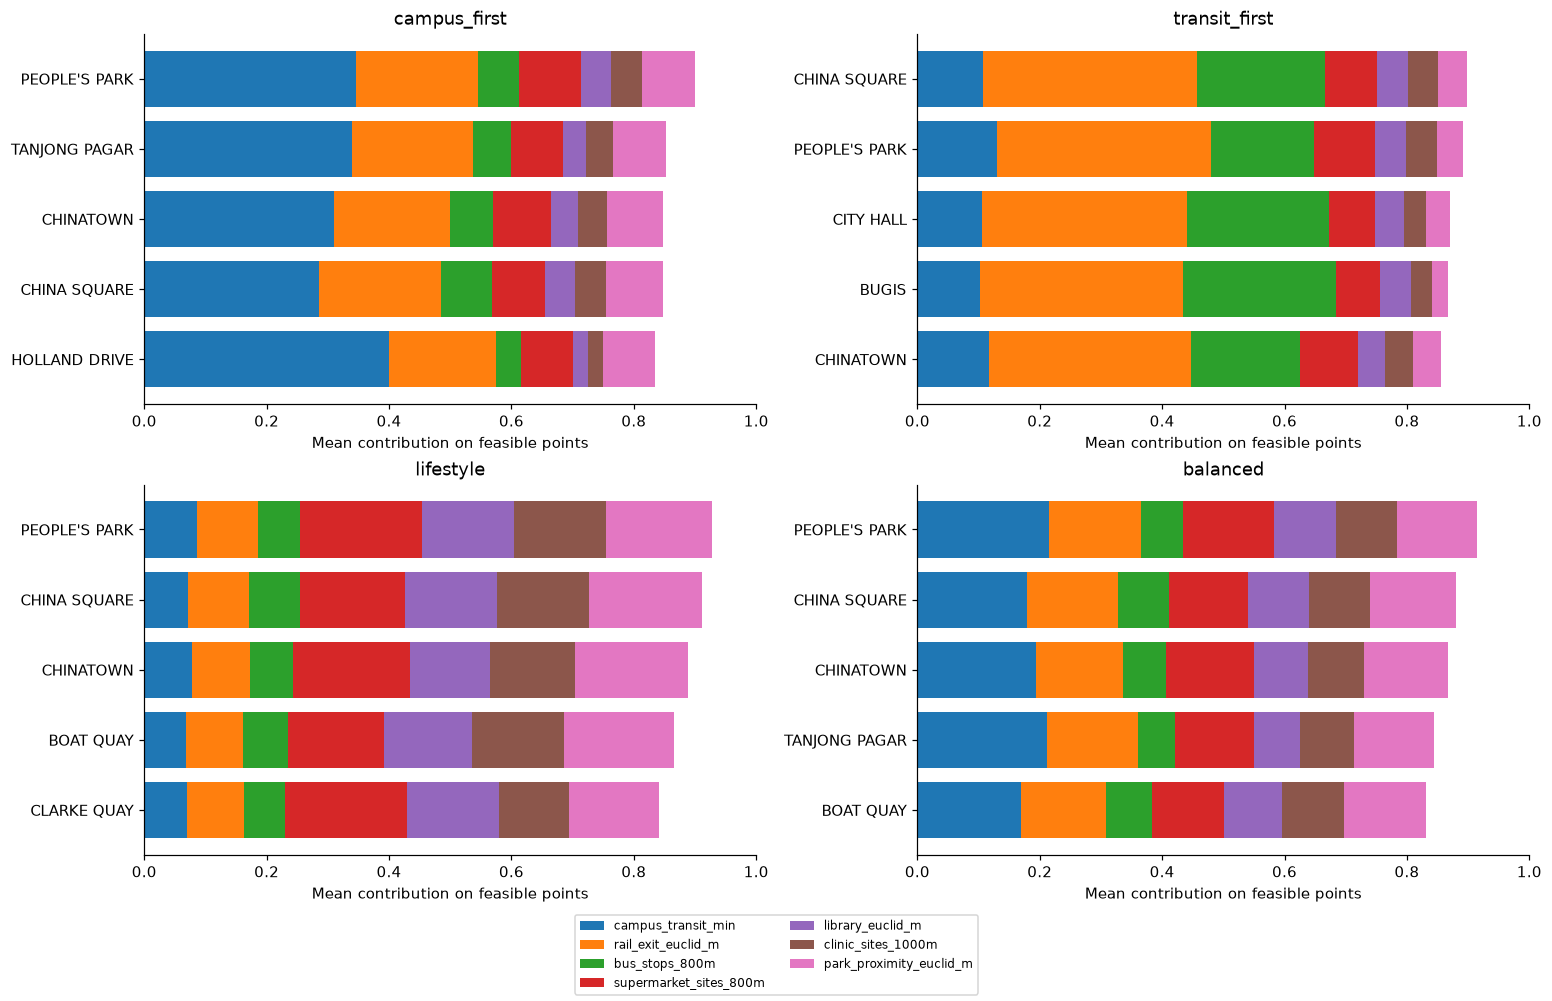

,scenario,top_k_jaccard,n_common,n_left,n_right,spearman,kendall
0,campus_first,0.666667,239,239,239,0.942224,0.799866
1,transit_first,0.428571,239,239,239,0.903469,0.737210
2,lifestyle,0.666667,239,239,239,0.943510,0.798530
3,balanced,1.000000,239,239,239,1.000000,1.000000


In [9]:
scenario_results = {}
for name, vector in SCENARIOS.items():
    scenario_result = recommend(baseline, params, vector, metadata=context_A)
    verify_bundle(scenario_result, EXPERIMENTS / f"scenario_{name}")
    scenario_results[name] = scenario_result
display(pd.DataFrame(SCENARIOS, index=FEATURES))
display(pd.concat([
    value["top5"][["rank", "unit_name", "score", "limited_support"]].assign(scenario=name)
    for name, value in scenario_results.items()
], ignore_index=True))
figure, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for axis, (name, value) in zip(axes.flat, scenario_results.items()):
    top = value["top5"].sort_values("rank", ascending=False)
    bottom = np.zeros(len(top))
    for feature in FEATURES:
        contribution = top["contribution_" + feature].to_numpy()
        axis.barh(top.unit_name, contribution, left=bottom, label=feature)
        bottom += contribution
    axis.set(title=name, xlabel="Mean contribution on feasible points", xlim=(0, 1))
handles, labels = axes.flat[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=2, fontsize=8)
plt.show()
display(pd.DataFrame([
    {"scenario": name, **compare_rankings(result["area_scores"], value["area_scores"])}
    for name, value in scenario_results.items()
]))

## 10. Reanalyse the completed 1,000 Monte Carlo draws
Read 1,000 completed Dirichlet vectors and 241,000 area rows (241 per draw). Recalculate Top5 frequency, median rank and P5/P95 from ranks, then verify the frozen summary. Regenerate weight vectors with seed=42, kappa=50 to check sampling; **do not call recommend 1,000 times by default**.

Frequency uses all 1,000 draws; ineligible units cannot be selected. Rank intervals use defined ranks. This measures conditional sensitivity to declared weights, not resident choice probability or conceptual validity.

,unit_id,selection_frequency,rank_median,rank_p05,rank_p95,unit_name,limited_support
136,OTSZ02,1.000,1.0,1.0,1.0,PEOPLE'S PARK,True
137,OTSZ03,1.000,3.0,2.0,3.0,CHINATOWN,False
138,OTSZ04,0.998,2.0,2.0,3.0,CHINA SQUARE,True
78,DTSZ09,0.901,4.0,4.0,6.0,TANJONG PAGAR,True
199,SRSZ03,0.602,5.0,4.0,8.0,BOAT QUAY,True
135,OTSZ01,0.174,7.0,5.0,10.0,PEARL'S HILL,False
198,SRSZ02,0.131,7.0,5.0,10.0,CLARKE QUAY,True
72,CLSZ06,0.065,11.0,5.0,20.0,CLEMENTI CENTRAL,False
76,DTSZ02,0.064,9.0,5.0,13.0,CITY HALL,False
152,QTSZ02,0.046,14.0,6.0,30.0,HOLLAND DRIVE,False


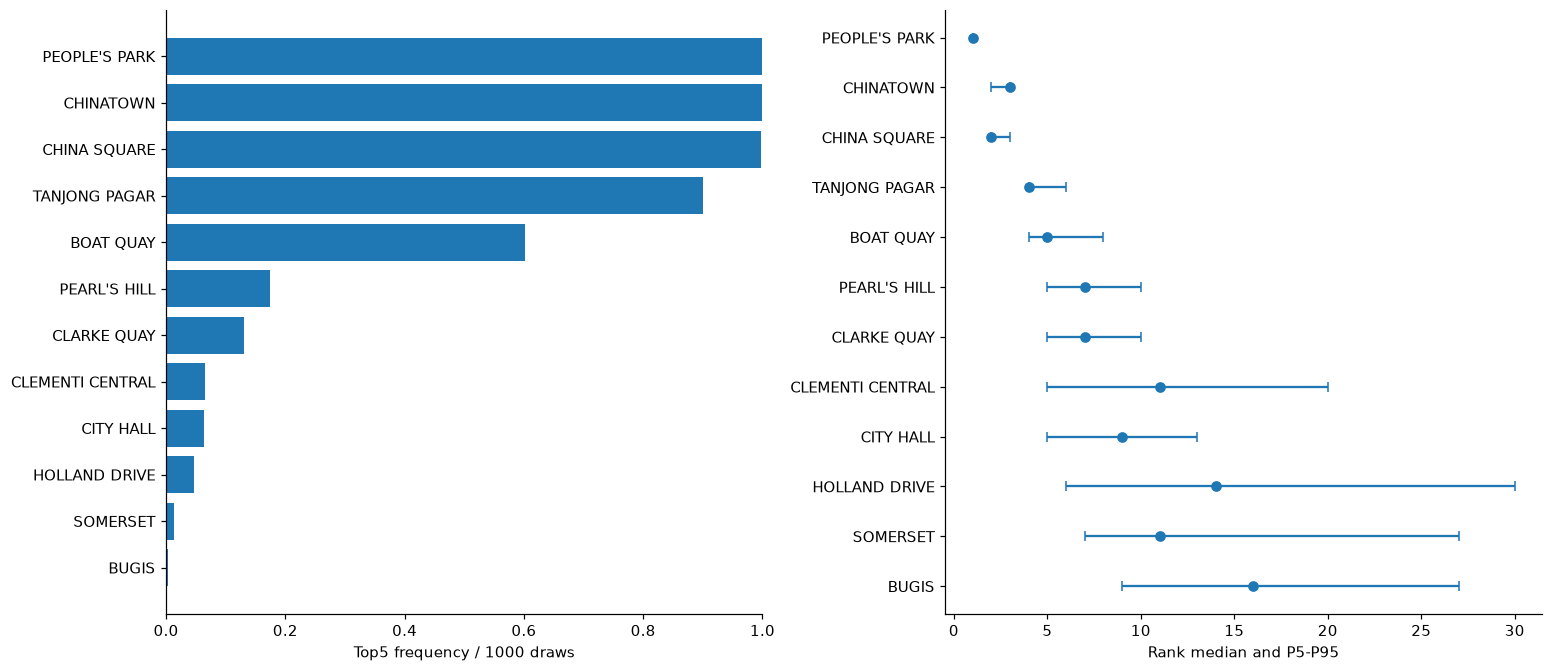

In [10]:
experiment_manifest = read_json(EXPERIMENTS / "experiment_manifest.json")
mc_weights = read_locations(EXPERIMENTS / "monte_carlo_weights.csv")
mc_ranks = read_locations(EXPERIMENTS / "monte_carlo_ranks.csv")
assert len(mc_weights) == experiment_manifest["draws"] == 1000
assert len(mc_ranks) == 1000 * 241 and mc_weights.run.is_unique
assert not mc_ranks.duplicated(["run", "unit_id"]).any()
assert mc_ranks.groupby("run").unit_id.size().eq(241).all()
mc_join = mc_ranks[["run", "result_id"]].drop_duplicates().merge(
    mc_weights[["run", "result_id"]], on="run", suffixes=("_ranks", "_weights"),
    validate="one_to_one",
)
assert len(mc_join) == 1000 and mc_join.result_id_ranks.eq(mc_join.result_id_weights).all()
np.testing.assert_allclose(mc_weights[list(FEATURES)].sum(axis=1), 1, atol=1e-14)
regenerated_weights = np.random.default_rng(experiment_manifest["seed"]).dirichlet(
    experiment_manifest["kappa"] * np.asarray(SCENARIOS["balanced"]), size=1000,
)
np.testing.assert_allclose(
    mc_weights.sort_values("run")[list(FEATURES)], regenerated_weights, rtol=1e-14, atol=1e-14,
)
mc_summary = mc_ranks.assign(selected=mc_ranks["rank"].le(5).fillna(False)).groupby(
    "unit_id", as_index=False,
).agg(
    selection_frequency=("selected", "mean"), rank_median=("rank", "median"),
    rank_p05=("rank", lambda x: x.quantile(.05)),
    rank_p95=("rank", lambda x: x.quantile(.95)),
)
assert_same_table(mc_summary, read_locations(EXPERIMENTS / "monte_carlo_frequency.csv"), ["unit_id"])
assert mc_ranks["rank"].le(5).groupby(mc_ranks.run).sum().eq(5).all()
names = result["area_scores"][["unit_id", "unit_name", "limited_support"]]
mc_display = mc_summary.merge(names, on="unit_id", validate="one_to_one")
display(mc_display.nlargest(15, "selection_frequency"))
figure, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
shown = mc_display.nlargest(12, "selection_frequency").sort_values("selection_frequency")
axes[0].barh(shown.unit_name, shown.selection_frequency)
axes[0].set(xlim=(0, 1), xlabel="Top5 frequency / 1000 draws")
rank_view = shown.dropna(subset=["rank_median"])
axes[1].errorbar(
    rank_view.rank_median, rank_view.unit_name,
    xerr=[rank_view.rank_median - rank_view.rank_p05, rank_view.rank_p95 - rank_view.rank_median],
    fmt="o", capsize=3,
)
axes[1].set(xlabel="Rank median and P5-P95")
plt.show()

## 11. OAT: 84 settings and 77 adjacent intervals
Set one weight to 0.05,0.10,…,0.60 and proportionally rescale the other six: 7×12=84 settings, 7×11=77 intervals. Read completed real ranks, verify weights and recompute all 77 comparisons. Top5 Jaccard<1 means different selections at the endpoints. Grid intervals are not exact critical weights. Correlations use commonly eligible areas.

,target_feature,interval_start,interval_end,top_k_jaccard,n_common,n_left,n_right,spearman,kendall
0,campus_transit_min,0.05,0.10,0.666667,239,239,239,0.994308,0.939383
5,campus_transit_min,0.30,0.35,0.666667,239,239,239,0.994141,0.939876
7,campus_transit_min,0.40,0.45,0.666667,239,239,239,0.995741,0.947751
9,campus_transit_min,0.50,0.55,0.666667,239,239,239,0.995695,0.950494
20,rail_exit_euclid_m,0.50,0.55,0.666667,239,239,239,0.998130,0.967301
24,bus_stops_800m,0.15,0.20,0.666667,239,239,239,0.994675,0.941212
26,bus_stops_800m,0.25,0.30,0.666667,239,239,239,0.995427,0.945290
28,bus_stops_800m,0.35,0.40,0.666667,239,239,239,0.995994,0.948455
30,bus_stops_800m,0.45,0.50,0.666667,239,239,239,0.996807,0.954924
36,supermarket_sites_800m,0.20,0.25,0.666667,239,239,239,0.996210,0.951408


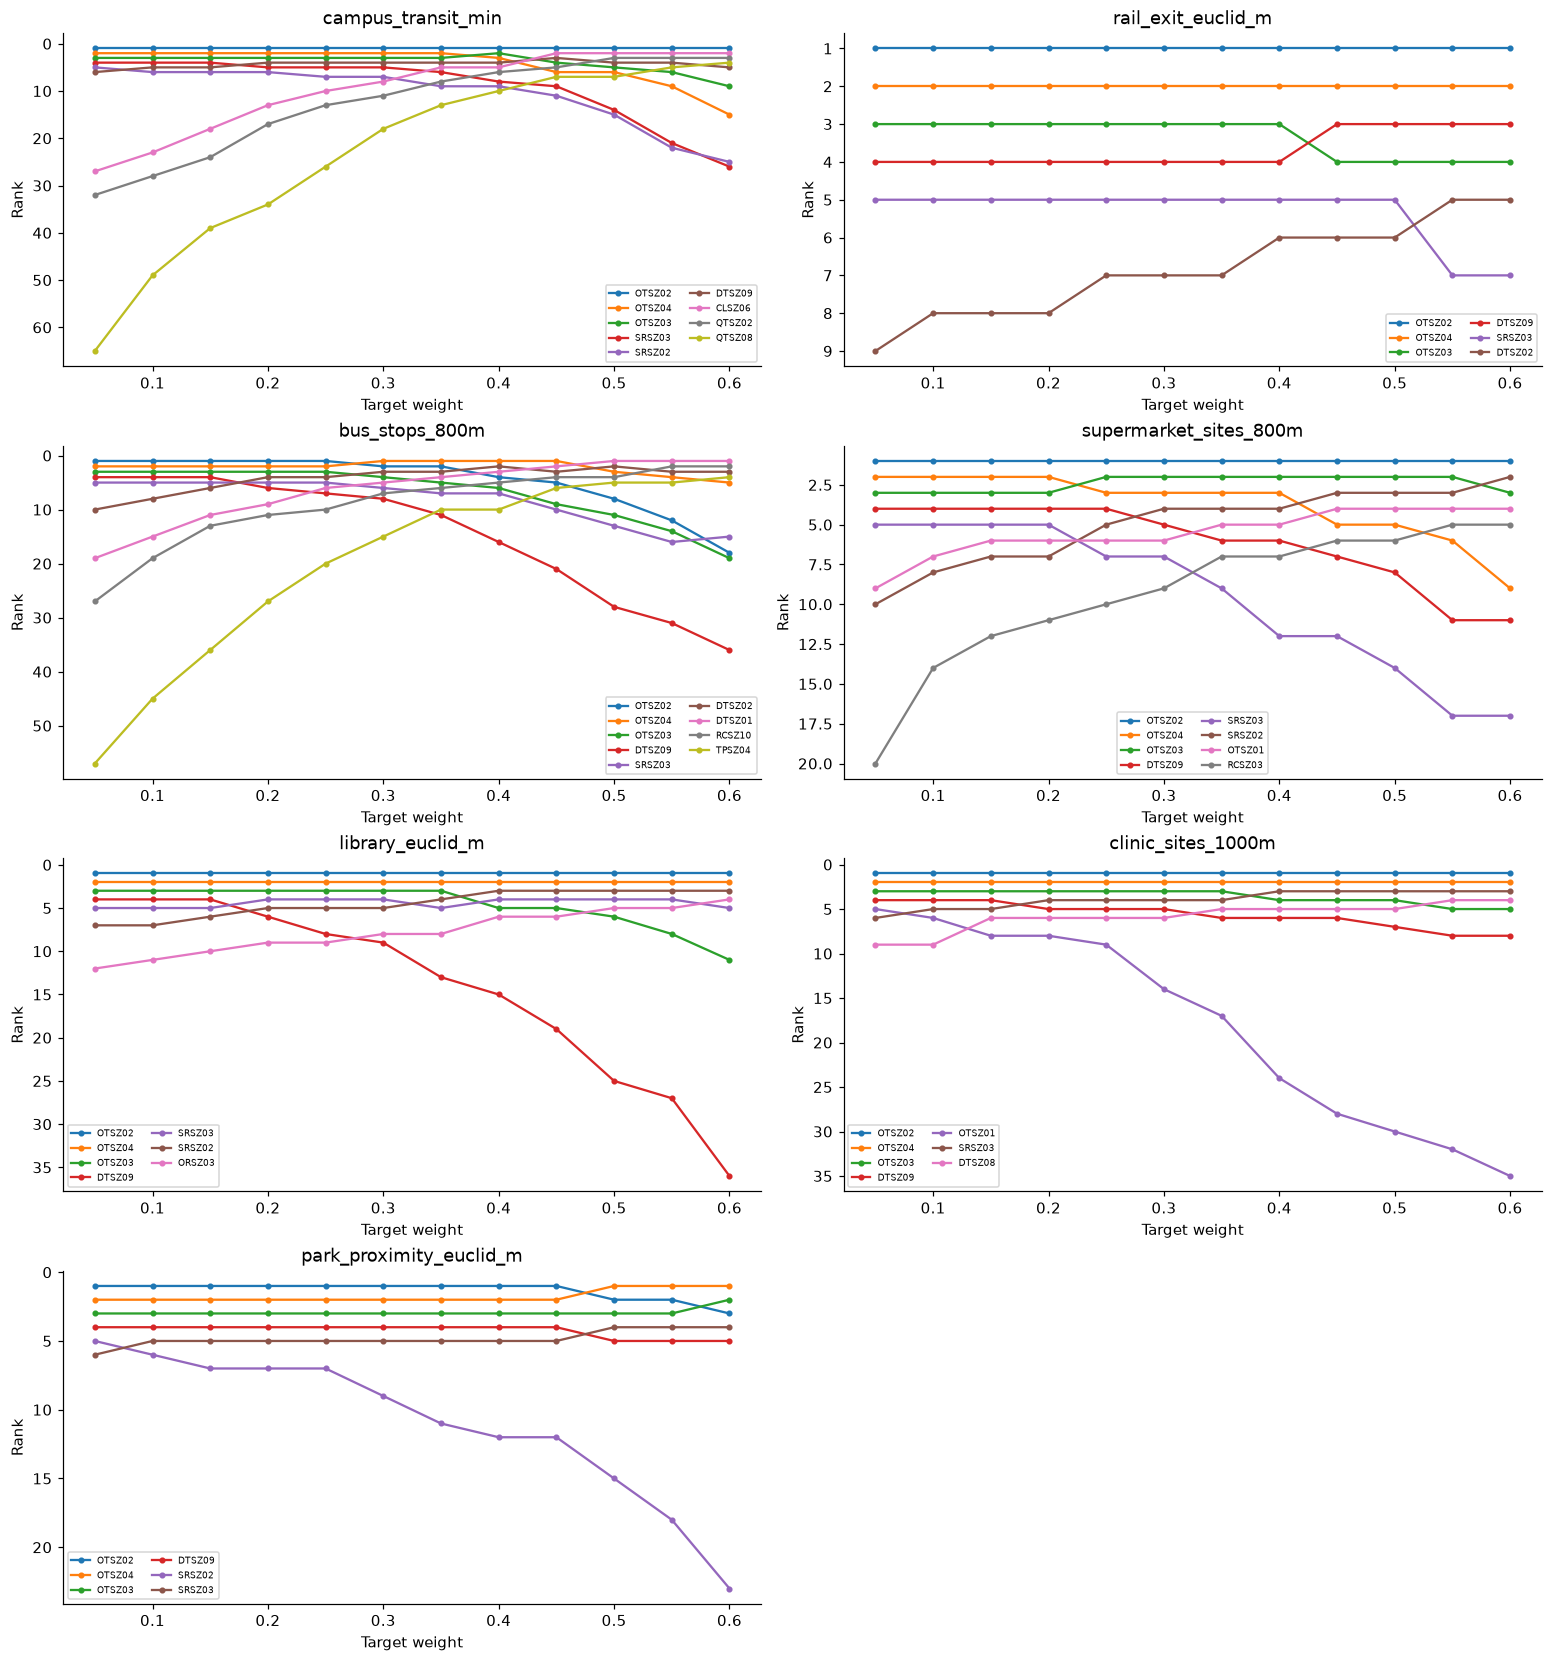

In [11]:
oat_weights = read_locations(EXPERIMENTS / "oat_weights.csv")
oat_ranks = read_locations(EXPERIMENTS / "oat_ranks.csv")
assert len(oat_weights) == 84 and len(oat_ranks) == 84 * 241
assert not oat_ranks.duplicated(["run", "unit_id"]).any()
balanced = np.asarray(SCENARIOS["balanced"])
switch_rows = []
for index, feature in enumerate(FEATURES):
    feature_weights = oat_weights[oat_weights.target_feature.eq(feature)].sort_values("target_weight")
    np.testing.assert_allclose(feature_weights.target_weight, np.arange(1, 13) / 20)
    for row in feature_weights.itertuples(index=False):
        expected_weights = balanced * ((1 - row.target_weight) / (1 - balanced[index]))
        expected_weights[index] = row.target_weight
        np.testing.assert_allclose(
            np.array([getattr(row, f) for f in FEATURES]), expected_weights, atol=1e-14,
        )
        run_ranks = oat_ranks[oat_ranks.run.eq(row.run)]
        assert len(run_ranks) == 241 and run_ranks.result_id.eq(row.result_id).all()
    ordered_rows = list(feature_weights.itertuples(index=False))
    for first, second in zip(ordered_rows, ordered_rows[1:]):
        switch_rows.append({
            "target_feature": feature, "interval_start": first.target_weight,
            "interval_end": second.target_weight,
            **compare_rankings(oat_ranks[oat_ranks.run.eq(first.run)],
                               oat_ranks[oat_ranks.run.eq(second.run)]),
        })
oat_switches = pd.DataFrame(switch_rows)
assert len(oat_switches) == 77
assert_same_table(oat_switches, read_locations(EXPERIMENTS / "oat_switch_intervals.csv"),
                  ["target_feature", "interval_start"])
display(oat_switches[oat_switches.top_k_jaccard.lt(1)])
oat_joined = oat_ranks.merge(
    oat_weights[["run", "target_feature", "target_weight"]], on="run", validate="many_to_one",
)
figure, axes = plt.subplots(4, 2, figsize=(14, 15), constrained_layout=True)
for axis, feature in zip(axes.flat, FEATURES):
    subset = oat_joined[oat_joined.target_feature.eq(feature)]
    for unit_id in subset.loc[subset["rank"].le(5), "unit_id"].unique():
        trajectory = subset[subset.unit_id.eq(unit_id)].sort_values("target_weight")
        axis.plot(trajectory.target_weight, trajectory["rank"], marker=".", label=unit_id)
    axis.set(title=feature, xlabel="Target weight", ylabel="Rank")
    axis.invert_yaxis()
    axis.legend(fontsize=6, ncol=2)
axes.flat[-1].set_visible(False)
plt.show()

## 12. Three spatial arms: actually recompute recommendations
All arms fix balanced weights, A normalization and a 60-minute cap. A→Subzone versus B→Subzone changes supplementation; B→Subzone versus B→cluster changes grouping on identical positions. Recompute and verify all bundles, then recalculate spatial overlap on common B positions.

Subzone and cluster IDs cannot be correlated directly. Position overlap, candidate-record overlap and unit sizes are different measures. Source records are not households or rental supply. Show selected_unit_support.csv with full candidate counts, bounding-box diagonal and sample support.

In [12]:
arms = {
    "A_subzone": recommend(baseline, params, SCENARIOS["balanced"],
                          max_commute_min=60, metadata=context_A),
    "B_subzone": recommend(matrix, params, SCENARIOS["balanced"],
                          max_commute_min=60, metadata={**context, "sample_set": "B"}),
    "B_cluster": recommend(matrix, params, SCENARIOS["balanced"], group_by="cluster_id",
                          max_commute_min=60, metadata={**context, "sample_set": "B"}),
}
arm_rows = []
for name, arm in arms.items():
    verify_bundle(arm, EXPERIMENTS / f"spatial_{name}")
    arm_rows.append({
        "arm": name, "planned": len(arm["point_scores"]),
        "eligible_units": int(arm["area_scores"].eligible.sum()),
        "top5_ids": ", ".join(arm["top5"].unit_id),
        "limited_support_in_top5": int(arm["top5"].limited_support.sum()),
    })
    display(read_locations(EXPERIMENTS / f"spatial_{name}" / "selected_unit_support.csv"))
display(pd.DataFrame(arm_rows))
spatial_overlap = compare_spatial_selections(
    matrix, set(arms["B_subzone"]["top5"].unit_id), set(arms["B_cluster"]["top5"].unit_id),
)
saved_spatial = read_json(EXPERIMENTS / "spatial_comparison.json")
for key, value in spatial_overlap.items():
    assert value == saved_spatial[key]
display(JSON(spatial_overlap))
display(pd.DataFrame([compare_rankings(
    arms["A_subzone"]["area_scores"], arms["B_subzone"]["area_scores"],
)]))

,unit_id,unit_name,unit_type,n_planned,n_valid,n_feasible,valid_share,conditional_feasible_share,...,rank,result_id,n_building_records,x_min,x_max,y_min,y_max,extent_diagonal_m
0,OTSZ02,PEOPLE'S PARK,subzone,1,1,1,1.0,1.0,...,1,mcda-b6e6cd4ce8cac47bd21bfce0,1,29024.0389,29024.0389,29618.5318,29618.5318,0.000000
1,OTSZ04,CHINA SQUARE,subzone,1,1,1,1.0,1.0,...,2,mcda-b6e6cd4ce8cac47bd21bfce0,9,29342.3228,29459.4706,29625.1200,29747.3647,169.314423
2,OTSZ03,CHINATOWN,subzone,6,6,6,1.0,1.0,...,3,mcda-b6e6cd4ce8cac47bd21bfce0,44,28779.7740,29712.1742,28591.9303,29472.5498,1282.521281
3,DTSZ09,TANJONG PAGAR,subzone,2,2,2,1.0,1.0,...,4,mcda-b6e6cd4ce8cac47bd21bfce0,7,29224.3219,29437.5567,28485.4326,28842.6727,416.040345
4,SRSZ03,BOAT QUAY,subzone,2,2,2,1.0,1.0,...,5,mcda-b6e6cd4ce8cac47bd21bfce0,3,29680.4739,29712.5044,29874.8622,30154.9385,281.901910


,unit_id,unit_name,unit_type,n_planned,n_valid,n_feasible,valid_share,conditional_feasible_share,...,rank,result_id,n_building_records,x_min,x_max,y_min,y_max,extent_diagonal_m
0,OTSZ02,PEOPLE'S PARK,subzone,1,1,1,1.0,1.0,...,1,mcda-60d9f07fd5e2cb4ec6380bd4,1,29024.0389,29024.0389,29618.5318,29618.5318,0.000000
1,OTSZ04,CHINA SQUARE,subzone,1,1,1,1.0,1.0,...,2,mcda-60d9f07fd5e2cb4ec6380bd4,9,29342.3228,29459.4706,29625.1200,29747.3647,169.314423
2,OTSZ03,CHINATOWN,subzone,7,7,7,1.0,1.0,...,3,mcda-60d9f07fd5e2cb4ec6380bd4,44,28779.7740,29712.1742,28591.9303,29472.5498,1282.521281
3,DTSZ09,TANJONG PAGAR,subzone,2,2,2,1.0,1.0,...,4,mcda-60d9f07fd5e2cb4ec6380bd4,7,29224.3219,29437.5567,28485.4326,28842.6727,416.040345
4,SRSZ03,BOAT QUAY,subzone,2,2,2,1.0,1.0,...,5,mcda-60d9f07fd5e2cb4ec6380bd4,3,29680.4739,29712.5044,29874.8622,30154.9385,281.901910


,unit_id,unit_name,unit_type,n_planned,n_valid,n_feasible,valid_share,conditional_feasible_share,...,rank,result_id,n_building_records,x_min,x_max,y_min,y_max,extent_diagonal_m
0,OTSZ02_C_39fc69d26fca,PEOPLE'S PARK · analysis cluster 39fc69d26fca,cluster,1,1,1,1.0,1.0,...,1,mcda-d18502107c3f0bc22373443f,1,29024.0389,29024.0389,29618.5318,29618.5318,0.000000
1,DTSZ09_C_df3846d8096e,TANJONG PAGAR · analysis cluster df3846d8096e,cluster,1,1,1,1.0,1.0,...,2,mcda-d18502107c3f0bc22373443f,2,29387.9866,29402.8604,28706.5975,28842.6727,136.885682
2,OTSZ01_C_3f0b940407d7,PEARL'S HILL · analysis cluster 3f0b940407d7,cluster,1,1,1,1.0,1.0,...,3,mcda-d18502107c3f0bc22373443f,1,28722.9535,28722.9535,29488.8835,29488.8835,0.000000
3,OTSZ03_C_1064ecff3b71,CHINATOWN · analysis cluster 1064ecff3b71,cluster,1,1,1,1.0,1.0,...,4,mcda-d18502107c3f0bc22373443f,2,28779.7740,28849.6203,29167.4837,29254.1138,111.280186
4,OTSZ03_C_c03a99682846,CHINATOWN · analysis cluster c03a99682846,cluster,1,1,1,1.0,1.0,...,5,mcda-d18502107c3f0bc22373443f,11,29003.5570,29227.5243,29244.1656,29472.5498,319.876061


,arm,planned,eligible_units,top5_ids,limited_support_in_top5
0,A_subzone,2176,167,"OTSZ02, OTSZ04, OTSZ03, DTSZ09, SRSZ03",4
1,B_subzone,2196,167,"OTSZ02, OTSZ04, OTSZ03, DTSZ09, SRSZ03",4
2,B_cluster,2196,276,"OTSZ02_C_39fc69d26fca, DTSZ09_C_df3846d8096e, ...",5


<IPython.core.display.JSON object>

,top_k_jaccard,n_common,n_left,n_right,spearman,kendall
0,1.0,167,167,167,0.99948,0.993363


## 13. Commute caps and qualification thresholds
Caps of 40/60 minutes use raw transit minutes. At 60 minutes compare verified_feasible_share of 25%,50%,75%, while valid_share remains ≥90%. conditional_feasible_share=n_feasible/n_valid differs from n_feasible/n_planned. Recompute and verify five bundles.

In [13]:
constraint_rows = []
for cap in (40, 60):
    cap_result = recommend(baseline, params, SCENARIOS["balanced"],
                           max_commute_min=cap, metadata=context_A)
    verify_bundle(cap_result, EXPERIMENTS / f"commute_cap_{cap}")
    constraint_rows.append({
        "case": f"cap_{cap}", "cap_min": cap, "min_verified_share": .5,
        "eligible": int(cap_result["area_scores"].eligible.sum()),
        "top5": ", ".join(cap_result["top5"].unit_name),
    })
for threshold in (.25, .5, .75):
    qualification = recommend(
        baseline, params, SCENARIOS["balanced"], max_commute_min=60,
        min_feasible_share=threshold, metadata=context_A,
    )
    verify_bundle(qualification, EXPERIMENTS / f"qualification_{int(threshold * 100)}")
    constraint_rows.append({
        "case": f"qualification_{threshold}", "cap_min": 60,
        "min_verified_share": threshold,
        "eligible": int(qualification["area_scores"].eligible.sum()),
        "top5": ", ".join(qualification["top5"].unit_name),
    })
display(pd.DataFrame(constraint_rows))
display(arms["A_subzone"]["area_scores"][[
    "unit_name", "n_planned", "n_valid", "n_feasible", "valid_share",
    "conditional_feasible_share", "verified_feasible_share", "eligible", "limited_support",
]].head(12))

,case,cap_min,min_verified_share,eligible,top5
0,cap_40,40,0.50,51,"PEOPLE'S PARK, TANJONG PAGAR, CLEMENTI CENTRAL..."
1,cap_60,60,0.50,167,"PEOPLE'S PARK, CHINA SQUARE, CHINATOWN, TANJON..."
2,qualification_0.25,60,0.25,178,"PEOPLE'S PARK, CHINA SQUARE, CHINATOWN, TANJON..."
3,qualification_0.5,60,0.50,167,"PEOPLE'S PARK, CHINA SQUARE, CHINATOWN, TANJON..."
4,qualification_0.75,60,0.75,152,"PEOPLE'S PARK, CHINA SQUARE, CHINATOWN, TANJON..."


,unit_name,n_planned,n_valid,n_feasible,valid_share,conditional_feasible_share,verified_feasible_share,eligible,limited_support
0,PEOPLE'S PARK,1,1,1,1.0,1.0,1.0,True,True
1,CHINA SQUARE,1,1,1,1.0,1.0,1.0,True,True
2,CHINATOWN,6,6,6,1.0,1.0,1.0,True,False
3,TANJONG PAGAR,2,2,2,1.0,1.0,1.0,True,True
4,BOAT QUAY,2,2,2,1.0,1.0,1.0,True,True
5,PEARL'S HILL,5,5,5,1.0,1.0,1.0,True,False
6,CLARKE QUAY,1,1,1,1.0,1.0,1.0,True,True
7,CITY HALL,4,4,4,1.0,1.0,1.0,True,False
8,CECIL,3,3,3,1.0,1.0,1.0,True,False
9,CLEMENTI CENTRAL,9,9,9,1.0,1.0,1.0,True,False


## 14. Optional: rerun all registered experiments
Skipped by default. RUN_FULL_EXPERIMENTS=True calls the public run_experiments seam with main CLI defaults: draws=1000, seed=42, kappa=50, retaining all weights/ranks and plots. Supply complete building membership and EPSG:3414 coordinates; write notebook_recomputed/experiments/ without network calls or normalization refitting. This can take tens of minutes, unlike default analysis.

In [14]:
if RUN_FULL_EXPERIMENTS:
    from ge5219.experiments import run_experiments
    buildings = gpd.read_file(PREPARED / "buildings.gpkg").to_crs(3414)
    coordinates = pd.DataFrame({
        "building_id": buildings.building_id,
        "x_3414": buildings.geometry.x, "y_3414": buildings.geometry.y,
    })
    full_membership = members.merge(coordinates, on="building_id", how="left", validate="one_to_one")
    rerun_manifest = run_experiments(
        matrix, params, RECOMPUTED / "experiments",
        building_membership=full_membership, metadata=context,
        draws=1000, seed=42, kappa=50.0, make_plots=True,
    )
    display(JSON(rerun_manifest))

## 15. Output contract, limits and next work
recommend returns point_scores, area_scores, top5 and metadata. Save three CSVs plus result_metadata.json, joined by one result_id. Maps, Agents and pages must consume that bundle without changing formulas, imputing values or inventing ranks. Browser selectors load registered results rather than score live. Status values are ok, data_coverage_insufficient, no_feasible_results and unsupported_destination; invalid parameters raise ValueError.

Housing reflects source classifications, not all planned housing or live rentals. 107 postal conflicts/214 records await adjudication; transit operation and facility addresses need review. Euclidean distances differ from network walking, stop counts do not measure routes/frequency, and park boundaries are not entrances. First-itinerary duration is not total elapsed time from requested departure. Several Top5 units have n_valid<3 and must keep the flag.

Desktop review covers 20 valid itineraries and one unavailable case, with six concerns. Same-provider checks are not independent truth. Prioritize independent routes and entrance evidence, conflict adjudication, facility review, stronger sampling and preference surveys, then explicitly version normalization and scenarios.

In [15]:
route_review = read_json(EXPERIMENTS / "route_review.json")
assert route_review["binding_status"] == "bound"
assert route_review["source_routes_sha256"] == context["source_routes_sha256"]
display(JSON({
    key: route_review[key] for key in [
        "status", "reviewed_count", "audited_count", "planned_count",
        "reviewed_concerns_count", "external_source_records_count", "binding_status",
        "method", "source_routes_sha256",
    ]
}))
display(pd.DataFrame({"pending_static_review": quality["readiness_blockers"]}))
display(JSON({
    "bundle_files": ["point_scores.csv", "area_scores.csv", "top5.csv", "result_metadata.json"],
    "result_id": result["metadata"]["result_id"],
    "verified_bundle_count": len(verified_bundles), "verified_bundles": verified_bundles,
}))

<IPython.core.display.JSON object>

,pending_static_review
0,107 postal conflicts require adjudication; hel...
1,Residential use is source-classification evide...
2,Identified unopened station excluded; remainin...
3,Non-reserve park/corridor categories and publi...
4,"Facility address precision, licence grouping a..."
5,"Destination review, public-transit coverage an..."


<IPython.core.display.JSON object>

## 16. Evidence from this execution
Recheck frozen hashes to prove reruns did not overwrite the baseline. scripts/execute_handover_notebooks.py collects the final JSON, launches a separate clean kernel for each notebook, retains outputs and writes outputs/audits/notebook_execution_check.json. Failed cells/assertions stop execution without reporting success. Default absence of API requests follows the disabled routing branch; it is not claimed as independent network traffic monitoring.

In [16]:
assert all(sha256(path) == expected for path, expected in frozen_hashes.items())
evidence = {
    "raw_source_read": True, "raw_file_count": len(raw_files),
    "raw_layers_inspected": len(layer_inventory), "raw_residence_records": len(raw_residences),
    "source_manifest_matches": all(source_hash_matches.values()),
    "matrix_matches_frozen": True, "normalization_matches_frozen": True,
    "baseline_matches_frozen": baseline_matches_frozen,
    "baseline_result_id": result["metadata"]["result_id"],
    "baseline_top5_ids": result["top5"].unit_id.tolist(),
    "verified_bundles": len(verified_bundles),
    "monte_carlo_draws_analysed": len(mc_weights),
    "monte_carlo_area_rows_analysed": len(mc_ranks),
    "monte_carlo_scores_rerun_by_default": False,
    "oat_settings_analysed": len(oat_weights),
    "oat_adjacent_intervals_recomputed": len(oat_switches),
    "frozen_files_unchanged": True,
    "run_prepare": RUN_PREPARE, "run_api": RUN_API,
    "run_full_experiments": RUN_FULL_EXPERIMENTS,
    "elapsed_seconds": round(time.perf_counter() - started, 3),
}
display(JSON(evidence))

<IPython.core.display.JSON object>